In [1]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#In this code we install and fool around with the gymnasium environment
#Jeremy Kedziora
#17 Nov 2025
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@

#In order to set up the kernel used in this notebook I created a virtual env by running the following at the command line:
#conda create -n py_Gym python=3.10
#conda activate py_Gym
#pip install ale-py
#pip install autorom[accept-rom-license]
#AutoROM --accept-license
#pip install "gymnasium[atari,accept-rom-license]" --force-reinstall
#pip install torch
#conda install matplotlib
#conda install ipykernel
#python -m ipykernel install --user --name=py_Gym --display-name="Python py_Gym"

#documentation for the space invaders environment is here: https://ale.farama.org/environments/space_invaders/


In [2]:
#@@@@@@@@@@@@@@@@@@@@@@@
#import useful libraries
#@@@@@@@@@@@@@@@@@@@@@@@
import gymnasium as gym
#from gymnasium.wrappers import AtariPreprocessing
import numpy as np
import ale_py
import cv2

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.distributions import Categorical

torch.autograd.set_detect_anomaly(True)


In [3]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#A function to set up the environment with automated preprocessing
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
def make_env(env_name = "ALE/SpaceInvaders-v5"):
    """A function to set up the environment
        Takes:
            env_name -- string, the name of the environment in ALE
        Returns:
            an environment set up with standard DQN atari preprocessing (grayscale 84x84, frame_skip=4)
    """
    env = gym.make(env_name, render_mode="rgb_array",frameskip=1)    #make the environment
    env = gym.wrappers.AtariPreprocessing(
        env,
        screen_size=84,
        grayscale_obs=True,
        frame_skip=4,
        scale_obs=True, #note these could also be normalized in the network
        terminal_on_life_loss=True)    #set up the preprocessing choices
    return env

#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
def reward_processing(env_reward,done,truncated):
    if not done and not truncated:
        env_reward += 0.25
    if not done and truncated:
        env_reward += 100
    return env_reward


In [ ]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#specify the deep learning model architecture for the actor and critic -- in this example they share input layers
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
class CNNActorCritic(nn.Module):
    def __init__(self, config):
        super().__init__()
        # Classic Atari-style conv net

        #set up the convolutional layers
        self.conv_1 = nn.Conv2d(in_channels = config['input']['input_channels']
                      , out_channels = config['conv_layer_1']['out_channels']
                      , kernel_size = config['conv_layer_1']['kernel_size']
                      , stride = config['conv_layer_1']['stride'])    #specify the first convolutional layer
        with torch.no_grad():    #no need to compute the gradient here
            dummy = torch.zeros(1, config['input']['input_channels'], 84, 84)    #generate a dummy input
            c1 = self.conv_1(dummy)    #push through the first convolutional layer
        self.ln1 = nn.LayerNorm(c1.shape[1:])   #set up the first layer normalization

        self.conv_2 = nn.Conv2d(in_channels = config['conv_layer_1']['out_channels']
                      , out_channels = config['conv_layer_2']['out_channels']
                      , kernel_size = config['conv_layer_2']['kernel_size']
                      , stride = config['conv_layer_2']['stride'])    #specify the second convolutional layer
        with torch.no_grad():    #still no need for gradients
            c2 = self.conv_2(c1)    #push the dummy through the second convolutional layer
        self.ln2 = nn.LayerNorm(c2.shape[1:])    #set up the second layer normalization

        self.conv_3 = nn.Conv2d(in_channels = config['conv_layer_2']['out_channels']
                      , out_channels = config['conv_layer_3']['out_channels']
                      , kernel_size = config['conv_layer_3']['kernel_size']
                      , stride = config['conv_layer_3']['stride'])    #specify the third convolutional layer
        with torch.no_grad():    #and yet still no need for gradients
            c3 = self.conv_3(c2)    #push the dummy through the third convolutional layer
        self.ln3 = nn.LayerNorm(c3.shape[1:])    #set up the fourth layer normalization

        #automatically compute convolutional output size (assuming 84x84 inputs)
        x = torch.zeros(1, config['input']['input_channels'], 84, 84)    #set up a dummy input
        with torch.no_grad():    #no need to compute the gradient here
            x = self.conv_1(x)    #push dummy through convolutional layer 1
            x = self.conv_2(x)    #push dummy through convolutional layer 2
            x = self.conv_3(x)    #push dummy through convolutional layer 3
        conv_out_dim = torch.flatten(x).shape[0]    #pull out the shape of the flattened convolutional layer output -- this is the input for the flattened stuff
        
        #set up the fully connected layers and the output layers for the actor and critic
        self.fc = nn.Linear(conv_out_dim, config['fully_connected_layer_neurons'])    #set up a fully connected layer
        self.actor_output = nn.Linear(config['fully_connected_layer_neurons'], config['n_actions'])    #set up the actor output layer
        self.critic_output = nn.Linear(config['fully_connected_layer_neurons'], 1)    #set up the critic output layer, in this case the state value

    def forward(self, h):
        x = F.relu(self.ln1(self.conv_1(h)))    #push history through convolutional layer 1
        x = F.relu(self.ln2(self.conv_2(x)))    #push first layer output through convolutional layer 2
        x = F.relu(self.ln3(self.conv_3(x)))    #push second layer output through convolutional layer 3
        x = torch.flatten(x)    #flatten
        
        x = F.relu(self.fc(x))    #push flattened output through the fully connected layer
        # logits = self.actor_output(x)    #push fully connected layer output through the actor output layer
        action_probs = F.softmax(self.actor_output(x), dim=-1)
        value = self.critic_output(x).squeeze(-1)    #push fully connected layer output through the critic output layer
        return action_probs, value

In [ ]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
class Agent:
    '''A class to build the agent'''
    
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def __init__(self, config):
        '''Set up the constructor
            Takes -- config
        '''
        self.config = config    #record the config parameters
        #TODO instantiate the actor-critic model
        self.model = CNNActorCritic(config['CNNconfig'])    #shared conv layers -> actor head pi(s|w_a) and critic head V(s|w_c)
        #TODO set the actor optimizer
        self.optimizer = optim.Adam(self.model.parameters(), lr=config['alpha'])    #one optimizer over the shared parameters -> a single gradient step
        self.reset_buffer()    #init the buffer

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def reset_buffer(self):
        '''Empty the buffer of transitions (s, a, r, s', done, I)'''
        self.buffer = {'states':[], 'actions':[], 'rewards':[], 'next_states':[], 'dones':[], 'discounts':[]}

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def store(self, h_t, action, reward, h_next, done, I):
        '''Store a single transition (s, a, r, s', done, I) in the buffer'''
        self.buffer['states'].append(h_t)
        self.buffer['actions'].append(action)
        self.buffer['rewards'].append(reward)
        self.buffer['next_states'].append(h_next)
        self.buffer['dones'].append(float(done))
        self.buffer['discounts'].append(I)

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def act(self, h_t):
        '''Sample an action a ~ pi(s, w_a)
            Takes:
                h_t -- np.array of shape (history_length, 84, 84)
            Returns:
                int, the sampled action
        '''
        with torch.no_grad():    #no gradients needed to act -- the states are re-run through the model at update time
            action_probs, _ = self.model(torch.as_tensor(h_t, dtype=torch.float32))
        return Categorical(probs=action_probs).sample().item()

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def init_history(self,obs,history_length):
        """A state-processing function to start the history at the beginning of an episode
            Takes:
                obs -- a single state
                history_length -- int, the number of states that should be in the history
            Returns:
                the history of stacked single states
        """
        history = []    #A list to store n frames of screen information
        for _ in range(history_length):    #loop over the history length
            # history.append(frame)    #init the history with 4 copies of the first frame
            history.append(obs)    #init the history with 4 copies of the first frame
        return history
    
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def reshape_history(self,history):
        """A state-processing function to put the history in the right shape
            Takes:
                history -- a list of screens
            Returns:
                a reshaped np.array of screen information
        """
        h_t = np.stack(history, axis=0)    #reshape the history to be in the right form for intake into the actor-critic model
        return h_t
    
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def update_history(self,obs,history):
        """A state-processing function to update the history
            Takes:
                obs -- the raw observation
                history -- a list of previous grayscaled, resized screens
            Returns:
                an updated list of grayscaled, resized screens
        """
        history.append(obs)    #add the new frame to the history
        history.pop(0)    #remove the oldest
        return history

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def make_objectives_A2C(self):
        """A function to make the objective for updating the actor and the critic
        Takes:
            buffer information internal to the agent class
        Returns:
            a tuple, first element is the policy objective and the second element is the value loss (MSE)
        """
        #TODO
        actions = torch.as_tensor(self.buffer['actions'], dtype=torch.long)
        rewards = torch.as_tensor(self.buffer['rewards'], dtype=torch.float32)
        dones = torch.as_tensor(self.buffer['dones'], dtype=torch.float32)
        I = torch.as_tensor(self.buffer['discounts'], dtype=torch.float32)

        #the model takes one state at a time, so push each stored state through it
        probs_list, values_list = [], []
        for h in self.buffer['states']:
            p, v = self.model(torch.as_tensor(h, dtype=torch.float32))    #pi(.|s, w_a) and V(s|w_c)
            probs_list.append(p)
            values_list.append(v)
        action_probs = torch.stack(probs_list)
        values = torch.stack(values_list)

        with torch.no_grad():    #V(s') is part of the target -- semi-gradient, no gradient through it
            next_values = torch.stack([self.model(torch.as_tensor(h, dtype=torch.float32))[1]
                                       for h in self.buffer['next_states']])

        #line 6: A <- r + gamma*V(s'|w_c) - V(s|w_c)   (V(s') = 0 if s' is terminal)
        targets = rewards + self.config['gamma'] * next_values * (1.0 - dones)
        advantage = targets - values

        #line 8: actor ascends I * A * grad ln pi(a|s, w_a) -- A is treated as a constant for the actor
        log_probs = Categorical(probs=action_probs).log_prob(actions)
        policy_objective = (I * advantage.detach() * log_probs).mean()

        #line 7: critic w_c <- w_c + alpha_c * A * grad V(s|w_c)  ==  gradient descent on 1/2 * A^2, i.e. the MSE to the target
        value_loss = F.mse_loss(values, targets)

        return policy_objective, value_loss

In [8]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#Set up the environment and the agent
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#set up the environment
env = make_env(env_name = "ALE/SpaceInvaders-v5")    # Create the environment, in this case space invaders
obs, info = env.reset()    #set up the environment
print("SpaceInvaders observation shape:", obs.shape)    #print S
print("SpaceInvaders action space:", env.action_space)    #print A(s)
# print("SpaceInvaders number of actions:", env.action_space.n)    #print |A(s)|

#set up the agent
history_length = 1
CNNconfig = {
    'input':{'input_channels':history_length,'input_size':84}
    ,'n_actions':6
    ,'conv_layer_1':{'out_channels':32,'kernel_size':8,'stride':4}
    ,'conv_layer_2':{'out_channels':64,'kernel_size':4,'stride':2}
    ,'conv_layer_3':{'out_channels':64,'kernel_size':3,'stride':1}
    ,'fully_connected_layer_neurons':512
}    #the config for the actor-critic architecture

Agent_config = {'history_length':history_length    #the number of screens to concatenate into the history
                ,'alpha':0.0001    #the learning rate
                ,'gamma':0.9    #the discount factor
                ,'beta':0.0    #the weight on entropy regularization
                ,'max_steps':200    #the max steps that an episode runs
                ,'B':5    #the episode batch size
                ,'CNNconfig':CNNconfig}

agent = Agent(Agent_config)


SpaceInvaders observation shape: (84, 84)
SpaceInvaders action space: Discrete(6)


In [12]:
n_episodes = 100
episode_rewards = []    #record the total reward for each episode
for epi in range(n_episodes):
    obs, info = env.reset()    #init up the environment
    history = agent.init_history(obs,Agent_config['history_length'])    #Init the history
    h_t = agent.reshape_history(history)    #reshape

    steps = 0
    total_reward = 0    #init the total reward accrued in an episode
    stop = False    #init the stopping condition
    while not stop:    #run and episode with random actions...
        #TODO generate action
        action = env.action_space.sample()
        #TODO evolve environment
        observation, reward, terminated, truncated, info = env.step(action)
        steps += 1    #increment the number of steps
        total_reward += reward    #add the reward

        stop = terminated or truncated    #update the stopping condition

        if stop:    #if the episode ended...
            obs, info = env.reset()    #reset the environment

    episode_rewards.append(total_reward)    #store this episode's total reward

episode_rewards = np.array(episode_rewards)
print(f"Mean reward: {episode_rewards.mean():.2f} | Std: {episode_rewards.std():.2f} | "
      f"Min: {episode_rewards.min():.0f} | Max: {episode_rewards.max():.0f}")

Mean reward: 53.65 | Std: 62.18 | Min: 0 | Max: 345


/tmp/ipykernel_205162/1011562028.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


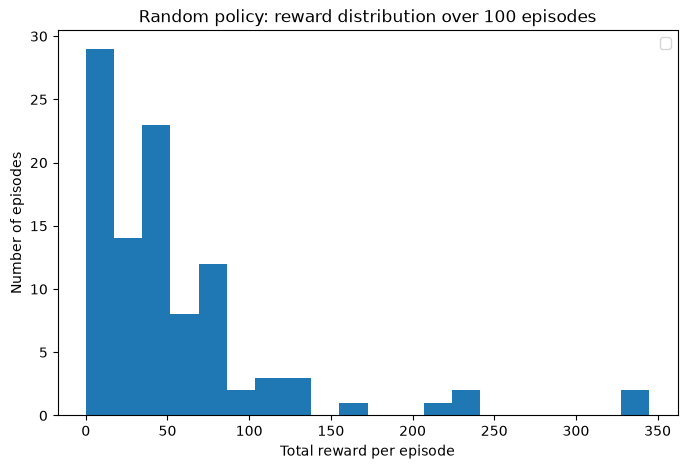

In [14]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#plot the distribution of total episode rewards
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(episode_rewards, bins=20)
ax.set_xlabel('Total reward per episode')
ax.set_ylabel('Number of episodes')
ax.set_title(f'Random policy: reward distribution over {len(episode_rewards)} episodes')
ax.legend()
plt.show()

# Training Agents to play Space Invaders with A2C

In [ ]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#a training loop with random actions and stacked screens
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
n_episodes = 20
for epi in range(n_episodes):
    obs, info = env.reset()    #init up the environment
    history = agent.init_history(obs,Agent_config['history_length'])    #Init the history
    h_t = agent.reshape_history(history)    #reshape

    steps = 0
    total_reward = 0    #init the total reward accrued in an episode
    stop = False    #init the stopping condition
    I = 1.0    #line 3: init discounting
    
    if epi % agent.config['B'] == 0:    #at the start of each batch of B episodes...
        agent.reset_buffer()    #reset the n-step buffer
    while not stop:    #run and episode with random actions...
        #TODO generate action
        action = agent.act(h_t)    #line 5: sample a ~ pi(s, w_a)
        #TODO evolve environment
        obs, reward, done, truncated, info = env.step(action)    #observe r and s'
        steps += 1    #increment the number of steps
        if steps >= agent.config['max_steps']:    #if the agent has survived to the end...
            truncated = True    #update the truncation condition
        stop = done or truncated    #update the stopping condition
        
        h_prev = h_t    #keep s before moving to s'
        history = agent.update_history(obs,history)    #add the new screen and drop the oldest
        h_t = agent.reshape_history(history)    #reshape
        
        total_reward += reward    #add the reward
        agent.store(h_prev, action, reward, h_t, done, I)    #record (s, a, r, s', done, I)
        I *= agent.config['gamma']    #line 9: I <- gamma * I
    
        if done or truncated:    #if the episode ended...
            obs, info = env.reset()    #reset the environment
    
    if (epi + 1) % agent.config['B'] == 0 or epi == n_episodes - 1:    #once B episodes are in the buffer...
        #TODO compute the policy objective and value loss
        policy_objective, value_loss = agent.make_objectives_A2C()
        #TODO assemble into the objective function
        loss = -policy_objective + value_loss    #minimize -J(w_a) + critic MSE; the shared layers get both gradients
        #TODO zero the gradients    
        agent.optimizer.zero_grad()
        #TODO backprop
        loss.backward()
        #TODO take a gradient step
        agent.optimizer.step()    #single gradient step updates actor and critic together
    
env.close()    #shut the environment down
    